# Unit00_Colab_Environment_Setup | Google Colab 環境設定與實作演練

本 Notebook 提供 Google Colab 雲端運算平台的實際操作演練，並內建跨平台相容設計（可同時於 **Google Colab** 與 **Windows 本地端 `PY310` 環境**中順利執行）。

## 目標
- 掌握本課程標準的跨環境路徑設定（Colab 自動掛載與 Symlink 架構 vs 本地端路徑）
- 檢查 Python 執行環境與系統硬體資源（CPU、記憶體、磁碟空間）
- 練習檔案管理、Google Drive 掛載與課程 GitHub 儲存庫同步指令
- 檢查預裝科學計算與機器學習套件版本，並練習安裝額外套件
- 測試 GPU / TPU 硬體加速資源與 TensorFlow 動態記憶體配置
- 完成一個完整的化工反應器數據探索、視覺化與多元線性回歸預測流程

配合教學講義：[Unit00_Colab_Environment_Setup.md](Unit00_Colab_Environment_Setup.md)

---
### 0. 環境設定

In [1]:
from pathlib import Path
import os

# ========================================
# 路徑設定 (兼容 Colab 與 Local)
# ========================================
UNIT_OUTPUT_DIR = 'P0_Unit00_Colab_Environment_Setup'

try:
    from google.colab import drive
    IN_COLAB = True
    print("✓ 偵測到 Colab 環境，準備掛載 Google Drive...")
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    IN_COLAB = False
    print("✓ 偵測到 Local 環境")

try:
    shortcut_path = '/content/ChemE-3590'
    os.remove(shortcut_path)
except (FileNotFoundError, OSError):
    pass

if IN_COLAB:
    source_path = Path('/content/drive/My Drive/Colab Notebooks/ChemE-3590')
    os.symlink(source_path, shortcut_path)
    shortcut_path = Path(shortcut_path)
    if source_path.exists():
        NOTEBOOK_DIR = shortcut_path / 'Part_0'
        OUTPUT_DIR   = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
        FIG_DIR      = OUTPUT_DIR / 'figs'
    else:
        print("⚠️ 找不到雲端 ChemE-3590 路徑，將使用當前目錄作為工作目錄")
        NOTEBOOK_DIR = Path.cwd()
        OUTPUT_DIR   = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
        FIG_DIR      = OUTPUT_DIR / 'figs'
else:
    NOTEBOOK_DIR = Path.cwd()
    OUTPUT_DIR   = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
    FIG_DIR      = OUTPUT_DIR / 'figs'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"\n✓ Notebook工作目錄: {NOTEBOOK_DIR}")
print(f"✓ 結果輸出目錄: {OUTPUT_DIR}")
print(f"✓ 圖檔輸出目錄: {FIG_DIR}")

✓ 偵測到 Local 環境

✓ Notebook工作目錄: D:\MyGit\ChemE-3590\Part_0
✓ 結果輸出目錄: D:\MyGit\ChemE-3590\Part_0\outputs\P0_Unit00_Colab_Environment_Setup
✓ 圖檔輸出目錄: D:\MyGit\ChemE-3590\Part_0\outputs\P0_Unit00_Colab_Environment_Setup\figs


---
### 1. 載入套件

In [2]:
import sys
import platform
import shutil
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf

# 設定隨機種子以確保結果可重現
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 繪圖樣式設定
plt.rcParams.update({
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'lines.linewidth': 2,
    'axes.unicode_minus': False,
})

print("✓ 套件載入完成")
print(f"  Python       版本: {sys.version.split()[0]}")
print(f"  numpy        版本: {np.__version__}")
print(f"  scipy        版本: {scipy.__version__}")
print(f"  pandas       版本: {pd.__version__}")
print(f"  matplotlib   版本: {matplotlib.__version__}")
print(f"  seaborn      版本: {sns.__version__}")
print(f"  scikit-learn 版本: {sklearn.__version__}")
print(f"  tensorflow   版本: {tf.__version__}")

✓ 套件載入完成
  Python       版本: 3.10.19
  numpy        版本: 1.26.4
  scipy        版本: 1.15.2
  pandas       版本: 2.3.3
  matplotlib   版本: 3.10.8
  seaborn      版本: 0.13.2
  scikit-learn 版本: 1.7.2
  tensorflow   版本: 2.10.1


---
### 2. 環境檢查與系統硬體資源

在開始進行數據分析或深度學習訓練前，先確認目前的 Python 執行環境、作業系統平台、CPU 型號、記憶體（RAM）容量與可用磁碟空間。

In [3]:
print("=== Python Environment & System Information ===")
print(f"Python Version    : {sys.version}")
print(f"Python Executable : {sys.executable}")
print(f"Operating System  : {platform.platform()}")
print(f"Architecture      : {platform.architecture()[0]} ({platform.machine()})")
print(f"Processor         : {platform.processor()}")

# 檢查系統記憶體 (RAM) 與磁碟空間 (跨平台相容)
print("\n=== Hardware Resource Summary ===")
if IN_COLAB or Path('/proc/meminfo').exists():
    with open('/proc/cpuinfo') as f:
        for line in f:
            if 'model name' in line:
                print(f"CPU Model         : {line.split(':')[1].strip()}")
                break
    with open('/proc/meminfo') as f:
        for line in f:
            if 'MemTotal' in line:
                mem_kb = int(line.split()[1])
                print(f"Total RAM         : {mem_kb / (1024**2):.2f} GB")
                break
elif platform.system() == 'Windows':
    import ctypes
    class MEMORYSTATUSEX(ctypes.Structure):
        _fields_ = [
            ("dwLength", ctypes.c_ulong),
            ("dwMemoryLoad", ctypes.c_ulong),
            ("ullTotalPhys", ctypes.c_ulonglong),
            ("ullAvailPhys", ctypes.c_ulonglong),
            ("ullTotalPageFile", ctypes.c_ulonglong),
            ("ullAvailPageFile", ctypes.c_ulonglong),
            ("ullTotalVirtual", ctypes.c_ulonglong),
            ("ullAvailVirtual", ctypes.c_ulonglong),
            ("sullAvailExtendedVirtual", ctypes.c_ulonglong),
        ]
    stat = MEMORYSTATUSEX(dwLength=ctypes.sizeof(MEMORYSTATUSEX))
    ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(stat))
    print(f"Total RAM         : {stat.ullTotalPhys / (1024**3):.2f} GB (Available: {stat.ullAvailPhys / (1024**3):.2f} GB)")

total_disk, used_disk, free_disk = shutil.disk_usage(NOTEBOOK_DIR)
print(f"Disk Space        : Total {total_disk / (1024**3):.1f} GB | Used {used_disk / (1024**3):.1f} GB | Free {free_disk / (1024**3):.1f} GB")

if IN_COLAB:
    print("\n✓ 目前在 Google Colab 雲端環境中執行")
else:
    print("\n✓ 目前在本地端 (Local) 環境中執行（所有單元程式碼皆相容雙環境）")

=== Python Environment & System Information ===
Python Version    : 3.10.19 | packaged by conda-forge | (main, Oct 22 2025, 22:23:22) [MSC v.1944 64 bit (AMD64)]
Python Executable : C:\Users\Yao-ChenChuang\miniconda3\envs\PY310\python.exe
Operating System  : Windows-10-10.0.26200-SP0
Architecture      : 64bit (AMD64)
Processor         : Intel64 Family 6 Model 85 Stepping 7, GenuineIntel

=== Hardware Resource Summary ===
Total RAM         : 127.69 GB (Available: 66.52 GB)
Disk Space        : Total 465.8 GB | Used 214.8 GB | Free 251.0 GB

✓ 目前在本地端 (Local) 環境中執行（所有單元程式碼皆相容雙環境）


---
### 3. 檔案系統、Google Drive 掛載與課程資料同步

在 Google Colab 中，預設工作目錄 `/content/` 為暫時性虛擬機空間（執行階段結束後即清除）。因此本課程採用 **Google Drive 雲端硬碟掛載**搭配 `git` 版本控制來永久保存課程教材與實驗結果。

In [4]:
print("=== Current Working Directory & Files ===")
print(f"Current Directory : {NOTEBOOK_DIR}")
print("\nDirectory Contents:")
for item in sorted(NOTEBOOK_DIR.iterdir()):
    item_type = "[DIR] " if item.is_dir() else "[FILE]"
    size_str = f"({item.stat().st_size / 1024:.1f} KB)" if item.is_file() else ""
    print(f"  {item_type} {item.name:40s} {size_str}")

=== Current Working Directory & Files ===
Current Directory : D:\MyGit\ChemE-3590\Part_0

Directory Contents:
  [DIR]  outputs                                  
  [FILE] PY310_environment.yml                    (0.6 KB)
  [FILE] README.md                                (21.5 KB)
  [FILE] Unit00_Colab_Environment_Setup.ipynb     (476.0 KB)
  [FILE] Unit00_Colab_Environment_Setup.md        (53.5 KB)
  [FILE] Unit00_Hermes_Agent_Command.md           (20.2 KB)
  [FILE] Unit00_Hermes_Agent_Setup.md             (40.3 KB)
  [FILE] Unit00_Local_Environment_Setup.ipynb     (351.9 KB)
  [FILE] Unit00_Local_Environment_Setup.md        (75.1 KB)


In [5]:
# Google Drive 狀態檢查與課程 GitHub 儲存庫同步指令說明
if IN_COLAB:
    drive_root = Path('/content/drive/MyDrive')
    if not drive_root.exists():
        drive_root = Path('/content/drive/My Drive')
    print(f"✓ Google Drive 已掛載於: {drive_root}")
    course_dir = drive_root / 'Colab Notebooks' / 'ChemE-3590'
    print(f"✓ 課程雲端專案路徑: {course_dir} (Exists: {course_dir.exists()})")
else:
    print("ℹ️ 目前為 Local 環境，無須掛載 Google Drive。")
    print("   若在 Google Colab 初次下載或更新課程資料，可於 Colab 儲存格執行以下指令：")
    print("   ------------------------------------------------------------------------")
    print("   # [初次下載課程資料]")
    print('   %cd "/content/drive/MyDrive/Colab Notebooks/"')
    print("   !git clone https://github.com/d9148408/ChemE-3590.git")
    print("\n   # [每週更新課程資料]")
    print('   %cd "/content/drive/MyDrive/Colab Notebooks/ChemE-3590/"')
    print("   !git fetch origin")
    print("   !git reset --hard origin/main")

ℹ️ 目前為 Local 環境，無須掛載 Google Drive。
   若在 Google Colab 初次下載或更新課程資料，可於 Colab 儲存格執行以下指令：
   ------------------------------------------------------------------------
   # [初次下載課程資料]
   %cd "/content/drive/MyDrive/Colab Notebooks/"
   !git clone https://github.com/d9148408/ChemE-3590.git

   # [每週更新課程資料]
   %cd "/content/drive/MyDrive/Colab Notebooks/ChemE-3590/"
   !git fetch origin
   !git reset --hard origin/main


---
### 4. 額外套件檢查與安裝示範

除了 NumPy、Pandas、Scikit-learn 與 TensorFlow 外，本課程在進階單元也會使用梯度提升樹套件（如 `xgboost`、`lightgbm`、`catboost`）。以下示範如何在程式中檢查套件是否已安裝，並在缺少時透過 `pip` 自動安裝。

In [6]:
import importlib
import subprocess

extra_packages = ['xgboost', 'lightgbm', 'catboost']

print("=== 檢查進階機器學習套件 ===")
for pkg in extra_packages:
    try:
        mod = importlib.import_module(pkg)
        print(f"✓ {pkg:10s} 已安裝，版本: {mod.__version__}")
    except ImportError:
        print(f"△ {pkg:10s} 未安裝，正在使用 pip 靜默安裝...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
        mod = importlib.import_module(pkg)
        print(f"✓ {pkg:10s} 安裝完成，版本: {mod.__version__}")

=== 檢查進階機器學習套件 ===
✓ xgboost    已安裝，版本: 1.7.6
✓ lightgbm   已安裝，版本: 4.6.0


✓ catboost   已安裝，版本: 1.2.7


---
### 5. GPU / TPU 運算資源檢查

在進行深度學習（Part 4：DNN、CNN、RNN）訓練時，啟用 GPU 硬體加速器可大幅縮短訓練時間。以下檢查 TensorFlow 的 GPU 可用性、設定動態記憶體配置（Memory Growth），並呼叫 `nvidia-smi` 查看顯示卡硬體狀態。

In [7]:
print("=== TensorFlow GPU / TPU 狀態檢查 ===")
print(f"TensorFlow Version: {tf.__version__}")

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"\n✓ 偵測到 {len(gpus)} 個可用 GPU:")
    for i, gpu in enumerate(gpus):
        print(f"  GPU {i}: {gpu.name}")
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("✓ GPU 記憶體動態分配 (Memory Growth) 已啟用")
    except RuntimeError as e:
        print(f"ℹ️ GPU 記憶體設定提示: {e}")
else:
    print("\n△ 未偵測到 GPU，目前使用 CPU 運算。")
    print("  （若在 Colab 需要 GPU，請至「執行階段」→「變更執行階段類型」→ 選擇「T4 GPU」）")

# 檢查 TPU (選用)
try:
    tpu = tf.distribute.cluster_resolver.TPUClusterResolver()
    print(f"✓ 偵測到 TPU: {tpu.master()}")
except ValueError:
    print("ℹ️ 未連接 TPU（本課程深度學習單元預設使用 GPU 或 CPU 即可完成訓練）")

=== TensorFlow GPU / TPU 狀態檢查 ===
TensorFlow Version: 2.10.1



✓ 偵測到 1 個可用 GPU:


  GPU 0: /physical_device:GPU:0
✓ GPU 記憶體動態分配 (Memory Growth) 已啟用
ℹ️ 未連接 TPU（本課程深度學習單元預設使用 GPU 或 CPU 即可完成訓練）


In [8]:
print("=== GPU Hardware Details (nvidia-smi) ===")
if shutil.which('nvidia-smi'):
    res = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
    # 僅顯示 GPU 硬體狀態摘要表，省略本機背景處理程序清單
    gpu_summary = res.stdout.strip().split('\n\n')[0]
    print(gpu_summary)
else:
    print("目前環境未偵測到 nvidia-smi 指令（無 NVIDIA GPU 或處於純 CPU 執行階段）。")

=== GPU Hardware Details (nvidia-smi) ===


Sat Oct 31 02:10:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 596.49                 Driver Version: 596.49         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4090      WDDM  |   00000000:68:00.0  On |                  Off |
|  0%   42C    P8             19W /  500W |    4257MiB /  24564MiB |      7%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

---
### 6. 實作範例：化工反應器數據分析與建模流程

接下來我們透過一個完整的**連續攪拌槽反應器 (CSTR) 數據分析案例**，示範在 Notebook 中從模擬數據生成、探索性資料分析 (EDA)、相關性檢驗到建立監督式多元線性回歸模型的端到端工作流程。

#### 6.1 產生模擬反應器操作數據

假設我們收集了 $N = 200$ 組反應器穩態操作數據，包含三個關鍵操作參數（自變數）：
1. **反應溫度**（ `Temperature` , $T$ ）：服從常態分布 $\mathcal{N}(350, 20^2)$ ，單位為 °C
2. **反應壓力**（ `Pressure` , $P$ ）：服從常態分布 $\mathcal{N}(5.0, 0.5^2)$ ，單位為 bar
3. **進料流量**（ `Flow_Rate` , $F$ ）：服從常態分布 $\mathcal{N}(100, 10^2)$ ，單位為 L/min

反應物**轉化率**（ `Conversion` , $y$ ）受上述三個操作參數線性影響，並包含隨機量測雜訊 $\varepsilon \sim \mathcal{N}(0, 0.05^2)$ ，物理範圍限制於 $[0, 1]$ 之間：

$$
y = \mathrm{clip}\left( 0.3 \times \frac{T - 300}{50} + 0.4 \times \frac{P - 4}{2} + 0.1 \times \frac{F - 90}{20} + \varepsilon, \, 0, \, 1 \right)
$$

將括號內的線性組合展開整理，可推導出未截斷前的**真實理論線性模型參數**：

$$
\begin{aligned}
y &= \beta_0 + \beta_1 T + \beta_2 P + \beta_3 F + \varepsilon \\
  &= -3.0500 + 0.0060 \, T + 0.2000 \, P + 0.0050 \, F + \varepsilon
\end{aligned}
$$

稍後我們訓練線性回歸模型時，即可檢驗模型從數據中學習到的迴歸係數是否能準確還原上述理論值（ $\beta_1 = 0.0060$ 、 $\beta_2 = 0.2000$ 、 $\beta_3 = 0.0050$ 、 $\beta_0 = -3.0500$ ）。

In [9]:
# 設定隨機種子，確保數據可重現
np.random.seed(SEED)
n_samples = 200

# 產生三個操作參數 (自變數)
temperature = np.random.normal(350, 20, n_samples)  # Temperature (degC)
pressure    = np.random.normal(5.0, 0.5, n_samples) # Pressure (bar)
flow_rate   = np.random.normal(100, 10, n_samples)  # Flow rate (L/min)

# 計算產物轉化率（受溫度、壓力與進料流量共同影響，並加上高斯量測雜訊）
conversion_raw = (
    0.3 * (temperature - 300) / 50 +
    0.4 * (pressure - 4.0) / 2.0 +
    0.1 * (flow_rate - 90) / 20.0 +
    np.random.normal(0, 0.05, n_samples)
)
conversion = np.clip(conversion_raw, 0.0, 1.0)  # 限制轉化率於合理物理範圍 [0, 1]

# 建立 DataFrame
data = pd.DataFrame({
    'Temperature': temperature,
    'Pressure': pressure,
    'Flow_Rate': flow_rate,
    'Conversion': conversion
})

print(f"✓ 模擬反應器數據產生完成！ Dataset shape: {data.shape}")
print(f"  超出 [0, 1] 被截斷的樣本數: {int(np.sum(conversion != conversion_raw))} 筆\n")
print("=== 前 5 筆觀測數據 (First 5 Rows) ===")
print(data.head().round(4).to_string())
print("\n=== 基本描述性統計量 (Descriptive Statistics) ===")
print(data.describe().round(4).to_string())

✓ 模擬反應器數據產生完成！ Dataset shape: (200, 4)
  超出 [0, 1] 被截斷的樣本數: 2 筆

=== 前 5 筆觀測數據 (First 5 Rows) ===


   Temperature  Pressure  Flow_Rate  Conversion
0     359.9343    5.1789    84.0557      0.6035
1     347.2347    5.2804    94.0062      0.5134
2     362.9538    5.5415   100.0524      0.7798
3     380.4606    5.5269   100.4698      0.9083
4     345.3169    4.3112    95.4993      0.3823

=== 基本描述性統計量 (Descriptive Statistics) ===
       Temperature  Pressure  Flow_Rate  Conversion
count     200.0000  200.0000   200.0000    200.0000
mean      349.1846    5.0429    99.1434      0.5493
std        18.6201    0.4935     9.9404      0.1650
min       297.6051    3.3794    75.2836      0.0565
25%       335.8974    4.6971    92.0612      0.4494
50%       349.9162    5.0394    99.2240      0.5574
75%       360.0170    5.3436   105.7209      0.6416
max       404.4034    6.9264   130.7888      1.0000


#### 6.2 資料探索與分布視覺化

透過 `2 x 3` 子圖同時檢視三個操作變數（ `Temperature` 、 `Pressure` 、 `Flow_Rate` ）的單變量直方圖分布（上排），以及各操作變數對產物轉化率（ `Conversion` ）的雙變量散佈圖與單變量線性趨勢線（下排）。

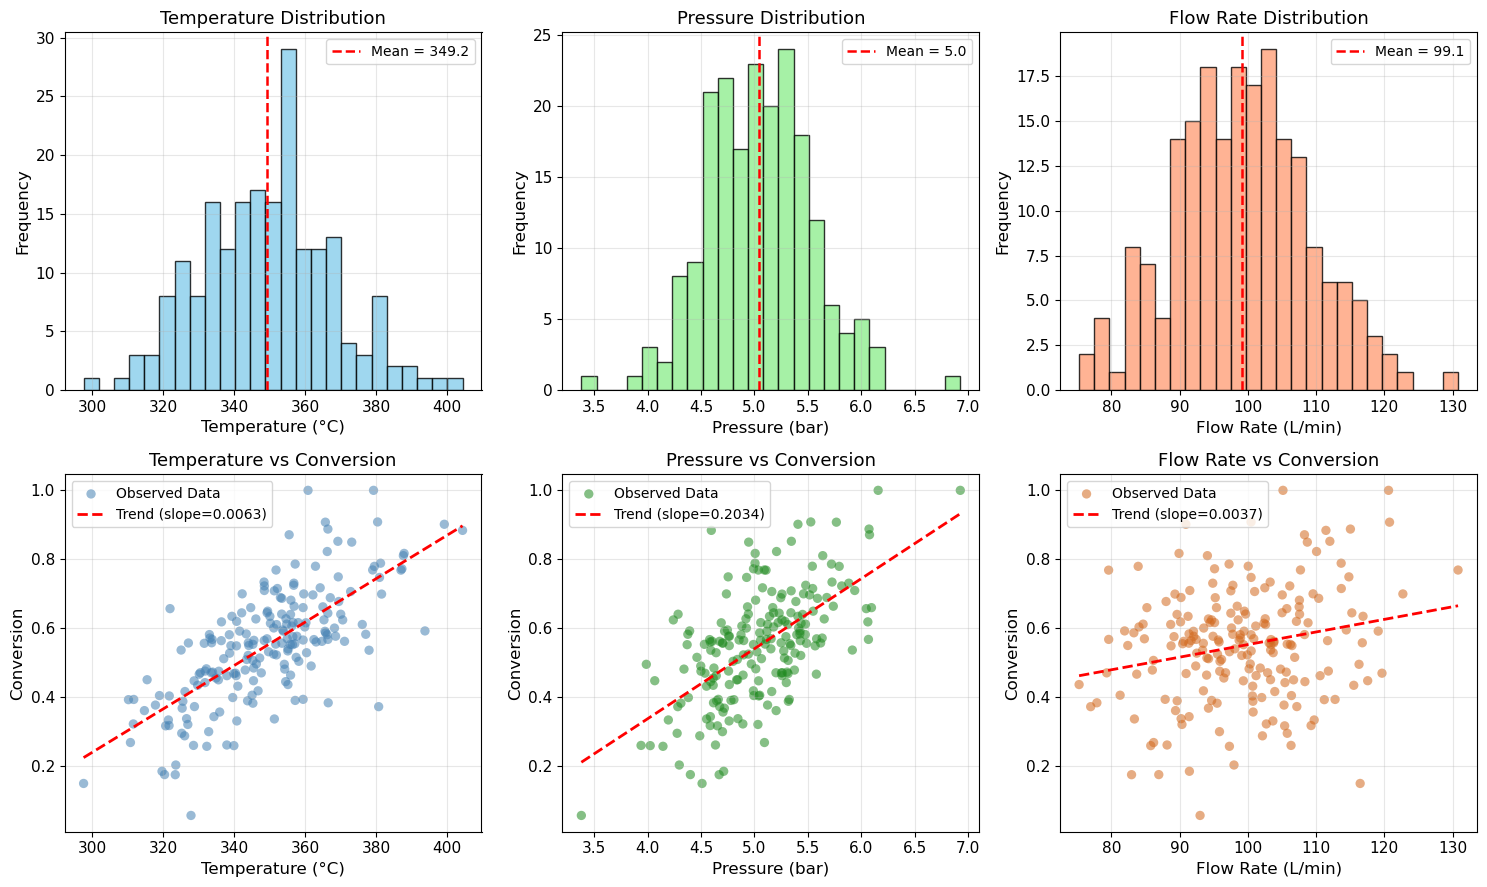

✓ 圖表已儲存至: D:\MyGit\ChemE-3590\Part_0\outputs\P0_Unit00_Colab_Environment_Setup\figs\reactor_data_distribution.png


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

features_info = [
    ('Temperature', 'Temperature (°C)', 'skyblue', 'steelblue'),
    ('Pressure', 'Pressure (bar)', 'lightgreen', 'forestgreen'),
    ('Flow_Rate', 'Flow Rate (L/min)', 'lightsalmon', 'chocolate')
]

for idx, (col, xlabel, hist_color, line_color) in enumerate(features_info):
    # 上排：直方圖分布與平均值標示
    ax_top = axes[0, idx]
    mean_val = data[col].mean()
    ax_top.hist(data[col], bins=25, color=hist_color, edgecolor='black', alpha=0.8)
    ax_top.axvline(mean_val, color='red', linestyle='--', linewidth=1.8, label=f'Mean = {mean_val:.1f}')
    ax_top.set_title(f'{col.replace("_", " ")} Distribution')
    ax_top.set_xlabel(xlabel)
    ax_top.set_ylabel('Frequency')
    ax_top.legend(loc='upper right')

    # 下排：對 Conversion 的散佈圖與線性趨勢線
    ax_bot = axes[1, idx]
    ax_bot.scatter(data[col], data['Conversion'], alpha=0.55, color=line_color, edgecolors='none', s=45, label='Observed Data')
    # 計算一階線性趨勢線
    z = np.polyfit(data[col], data['Conversion'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(data[col].min(), data[col].max(), 100)
    ax_bot.plot(x_line, p(x_line), 'r--', linewidth=2, label=f'Trend (slope={z[0]:.4f})')
    ax_bot.set_title(f'{col.replace("_", " ")} vs Conversion')
    ax_bot.set_xlabel(xlabel)
    ax_bot.set_ylabel('Conversion')
    ax_bot.legend(loc='upper left')

plt.tight_layout()
dist_fig_path = FIG_DIR / 'reactor_data_distribution.png'
plt.savefig(dist_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ 圖表已儲存至: {dist_fig_path}")

**圖表結果分析**：
- **上排直方圖**：三個操作變數皆呈現對稱的鐘形常態分布，樣本平均值分別為溫度 $349.18$ °C、壓力 $5.04$ bar、進料流量 $99.14$ L/min，與設定之母體參數（ $350, 5.0, 100$ ）高度吻合。
- **下排散佈圖與趨勢線**：
  - `Temperature vs Conversion` 呈現最明顯的正向斜率趨勢（單變量趨勢斜率為 $0.0063$ ，單位：1/°C），資料點緊密圍繞趨勢線。
  - `Pressure vs Conversion` 同樣呈現顯著正相關（單變量趨勢斜率為 $0.2034$ ，單位：1/bar）。
  - `Flow_Rate vs Conversion` 的散佈點較為發散（單變量趨勢斜率為 $0.0037$ ，單位：min/L），這是因為流量對轉化率的真實貢獻變異（標準化效應 $0.1 \times \frac{10}{20} = 0.05$ ）小於溫度（ $0.3 \times \frac{20}{50} = 0.12$ ）與壓力（ $0.4 \times \frac{0.5}{2} = 0.10$ ）所造成。

#### 6.3 相關性矩陣分析

計算各變數間的皮爾森相關係數（Pearson Correlation Coefficient, $r$ ），並繪製相關性熱力圖（Correlation Heatmap）以量化線性關聯強度。

=== Pearson Correlation Matrix ===
             Temperature  Pressure  Flow_Rate  Conversion
Temperature       1.0000    0.0951    -0.1342      0.7107
Pressure          0.0951    1.0000    -0.0326      0.6082
Flow_Rate        -0.1342   -0.0326     1.0000      0.2203
Conversion        0.7107    0.6082     0.2203      1.0000


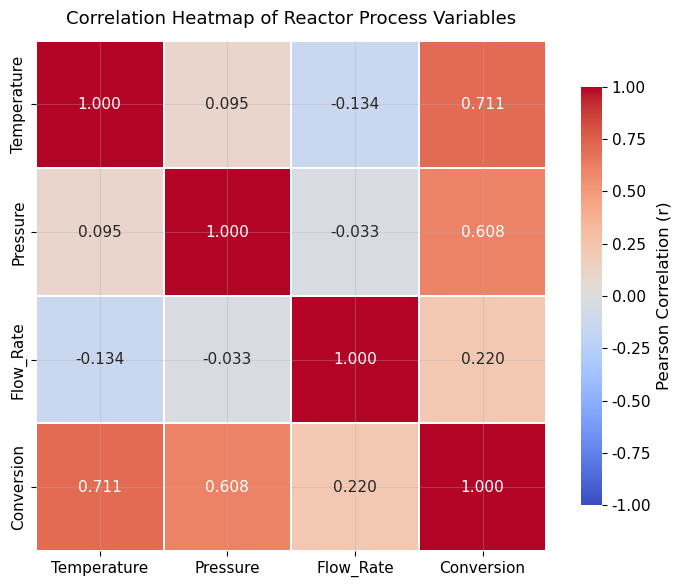

✓ 熱力圖已儲存至: D:\MyGit\ChemE-3590\Part_0\outputs\P0_Unit00_Colab_Environment_Setup\figs\correlation_heatmap.png


In [11]:
correlation_matrix = data.corr()

print("=== Pearson Correlation Matrix ===")
print(correlation_matrix.round(4).to_string())

plt.figure(figsize=(7.5, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    vmin=-1.0,
    vmax=1.0,
    square=True,
    linewidths=1.2,
    cbar_kws={"shrink": 0.82, "label": "Pearson Correlation (r)"}
)
plt.title('Correlation Heatmap of Reactor Process Variables', pad=12)
plt.tight_layout()
corr_fig_path = FIG_DIR / 'correlation_heatmap.png'
plt.savefig(corr_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ 熱力圖已儲存至: {corr_fig_path}")

**相關性分析結論**：
1. **自變數間彼此獨立**： `Temperature` 、 `Pressure` 與 `Flow_Rate` 兩兩之間的相關係數絕對值皆小於 $0.14$ （分別為 $0.0951$ 、 $-0.1342$ 、 $-0.0326$ ），確認無多重共線性（Multicollinearity）問題。
2. **對產物轉化率的影響排序**：
   - **反應溫度**（ $r = 0.7107$ ）：影響最顯著的第一主因。
   - **反應壓力**（ $r = 0.6082$ ）：次要關鍵操作參數。
   - **進料流量**（ $r = 0.2203$ ）：具有弱至中度正相關，在建立多元回歸模型時仍應納入以完整捕捉系統變異。

#### 6.4 建立多元線性回歸模型與係數驗證

將數據以 $80\% : 20\%$ 比例切分為訓練集（ $160$ 筆）與測試集（ $40$ 筆），使用普通最小平方法（Ordinary Least Squares, OLS）擬合多元線性回歸模型，並以均方誤差（ $\mathrm{MSE}$ ）、均方根誤差（ $\mathrm{RMSE}$ ）、平均絕對誤差（ $\mathrm{MAE}$ ）及決定係數（ $R^2$ ）評估模型表現：

$$
\mathrm{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2, \quad \mathrm{RMSE} = \sqrt{\mathrm{MSE}}, \quad \mathrm{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|, \quad R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}
$$

In [12]:
# 準備特徵矩陣 X 與目標向量 y
X = data[['Temperature', 'Pressure', 'Flow_Rate']]
y = data['Conversion']

# 分割訓練集 (80%) 與測試集 (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

print("=== Dataset Split ===")
print(f"Training set : {X_train.shape[0]} samples")
print(f"Test set     : {X_test.shape[0]} samples")

# 建立並訓練多元線性回歸模型
model = LinearRegression()
model.fit(X_train, y_train)

# 進行訓練集與測試集預測
y_train_pred = model.predict(X_train)
y_test_pred  = model.predict(X_test)

# 計算評估指標
mse_train  = mean_squared_error(y_train, y_train_pred)
rmse_train = np.sqrt(mse_train)
r2_train   = r2_score(y_train, y_train_pred)

mse_test   = mean_squared_error(y_test, y_test_pred)
rmse_test  = np.sqrt(mse_test)
mae_test   = mean_absolute_error(y_test, y_test_pred)
r2_test    = r2_score(y_test, y_test_pred)

print("\n=== Model Evaluation Metrics ===")
print(f"Train Set -> MSE: {mse_train:.4f} | RMSE: {rmse_train:.4f} | R^2: {r2_train:.4f}")
print(f"Test Set  -> MSE: {mse_test:.4f} | RMSE: {rmse_test:.4f} | MAE: {mae_test:.4f} | R^2: {r2_test:.4f}")

# 比較模型估計係數與理論真實係數
true_params = {'Temperature': 0.0060, 'Pressure': 0.2000, 'Flow_Rate': 0.0050, 'Intercept': -3.0500}
est_params  = {
    'Temperature': model.coef_[0],
    'Pressure': model.coef_[1],
    'Flow_Rate': model.coef_[2],
    'Intercept': model.intercept_
}

coef_df = pd.DataFrame({
    'Parameter': list(true_params.keys()),
    'True_Value': list(true_params.values()),
    'Estimated_Value': [est_params[k] for k in true_params.keys()],
})
coef_df['Abs_Error'] = (coef_df['Estimated_Value'] - coef_df['True_Value']).abs()
coef_df['Rel_Error (%)'] = (coef_df['Abs_Error'] / coef_df['True_Value'].abs()) * 100

print("\n=== Model Coefficients vs. Theoretical True Values ===")
print(coef_df.round(4).to_string(index=False))

=== Dataset Split ===
Training set : 160 samples
Test set     : 40 samples

=== Model Evaluation Metrics ===
Train Set -> MSE: 0.0026 | RMSE: 0.0513 | R^2: 0.9044
Test Set  -> MSE: 0.0019 | RMSE: 0.0437 | MAE: 0.0349 | R^2: 0.9236

=== Model Coefficients vs. Theoretical True Values ===
  Parameter  True_Value  Estimated_Value  Abs_Error  Rel_Error (%)
Temperature       0.006           0.0062     0.0002         3.9908
   Pressure       0.200           0.1823     0.0177         8.8532
  Flow_Rate       0.005           0.0054     0.0004         8.0243
  Intercept      -3.050          -3.0826     0.0326         1.0689


#### 6.5 預測結果視覺化（Parity Plot 與殘差分析）

繪製測試集的**實際轉化率 vs. 預測轉化率對角圖（Parity Plot）**以及**殘差分布圖（Residual Plot）**，驗證模型預測是否存在系統性偏差。

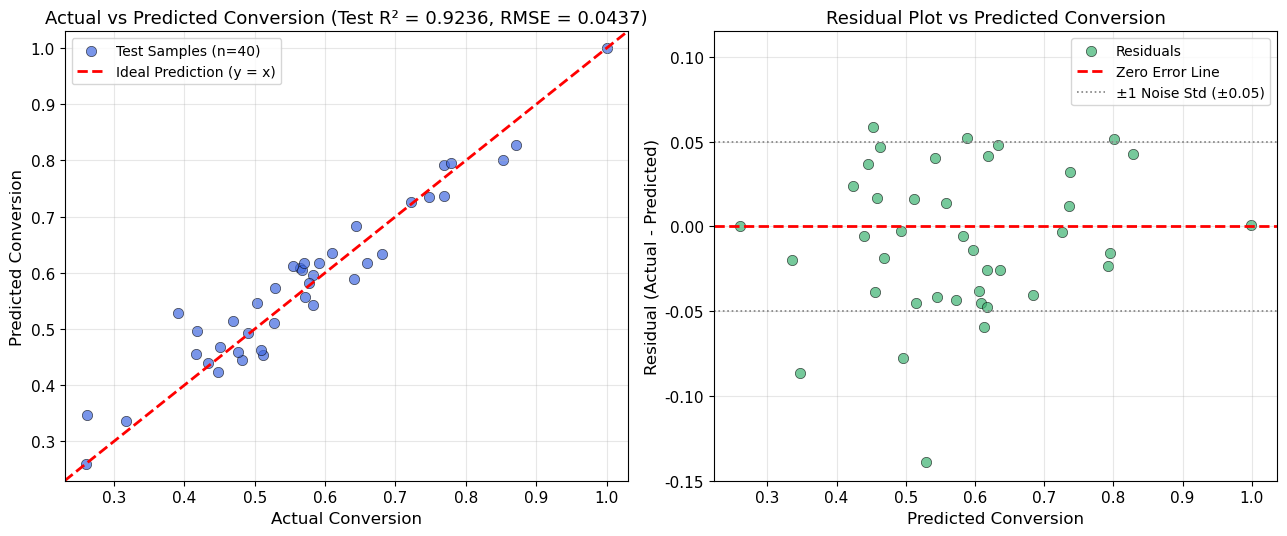

✓ 預測結果圖表已儲存至: D:\MyGit\ChemE-3590\Part_0\outputs\P0_Unit00_Colab_Environment_Setup\figs\actual_vs_predicted.png


In [13]:
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# 左圖：Parity Plot (Actual vs Predicted)
ax1 = axes[0]
ax1.scatter(y_test, y_test_pred, alpha=0.7, s=55, color='royalblue', edgecolors='black', linewidth=0.5, label='Test Samples (n=40)')
min_val = min(y_test.min(), y_test_pred.min()) - 0.03
max_val = max(y_test.max(), y_test_pred.max()) + 0.03
ax1.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Prediction (y = x)')
ax1.set_xlim(min_val, max_val)
ax1.set_ylim(min_val, max_val)
ax1.set_xlabel('Actual Conversion')
ax1.set_ylabel('Predicted Conversion')
ax1.set_title(f'Actual vs Predicted Conversion (Test R² = {r2_test:.4f}, RMSE = {rmse_test:.4f})')
ax1.legend(loc='upper left')

# 右圖：Residual Plot (Residuals vs Predicted)
ax2 = axes[1]
ax2.scatter(y_test_pred, residuals, alpha=0.7, s=55, color='mediumseagreen', edgecolors='black', linewidth=0.5, label='Residuals')
ax2.axhline(0, color='red', linestyle='--', lw=2, label='Zero Error Line')
ax2.axhline(0.05, color='gray', linestyle=':', lw=1.2, label='±1 Noise Std (±0.05)')
ax2.axhline(-0.05, color='gray', linestyle=':', lw=1.2)
ax2.set_ylim(-0.15, 0.115)
ax2.set_xlabel('Predicted Conversion')
ax2.set_ylabel('Residual (Actual - Predicted)')
ax2.set_title('Residual Plot vs Predicted Conversion')
ax2.legend(loc='upper right')

plt.tight_layout()
pred_fig_path = FIG_DIR / 'actual_vs_predicted.png'
plt.savefig(pred_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ 預測結果圖表已儲存至: {pred_fig_path}")

**模型評估與圖表討論**：
1. **極高的預測解釋力**：測試集決定係數達 $R^2 = 0.9236$ （訓練集 $R^2 = 0.9044$ ），測試集均方根誤差 $\mathrm{RMSE} = 0.0437$ （訓練集 $\mathrm{RMSE} = 0.0513$ ），與數據生成時設定的高斯量測雜訊標準差（ $\sigma = 0.0500$ ）高度一致，代表模型已將所有可解釋的確定性規律學習完畢，剩餘誤差純粹來自隨機量測雜訊。
2. **物理參數準確還原**：對比模型學到的迴歸係數與理論真實值：
   - 溫度斜率 $\hat{\beta}_1 = 0.0062$ （理論值 $0.0060$ ，相對誤差僅 $3.99\%$ ）
   - 壓力斜率 $\hat{\beta}_2 = 0.1823$ （理論值 $0.2000$ ，相對誤差僅 $8.85\%$ ）
   - 流量斜率 $\hat{\beta}_3 = 0.0054$ （理論值 $0.0050$ ，相對誤差僅 $8.02\%$ ）
   - 截距項 $\hat{\beta}_0 = -3.0826$ （理論值 $-3.0500$ ，相對誤差僅 $1.07\%$ ）
3. **殘差隨機性檢驗**：由右圖（Residual Plot）可見，殘差均勻且隨機地分布於零誤差線（Zero Error Line）上下 $\pm 0.05$ 區間內，無任何漏斗形（異質變異數）或二次曲線型態，證實線性模型假設完全成立。

---
### 7. 檔案儲存與下載示範

分析完成後，我們將模擬數據與預測結果儲存至標準輸出目錄 `OUTPUT_DIR` 中。若在 Google Colab 環境中，因為 `OUTPUT_DIR` 已透過符號連結指向 Google Drive，儲存於此目錄的檔案會**自動永久保存於雲端硬碟**；若需額外下載至本地電腦，則可呼叫 `google.colab.files.download()`。

In [14]:
# 將模擬反應器數據儲存為 CSV 檔案至標準輸出目錄
csv_output_path = OUTPUT_DIR / 'reactor_data.csv'
data.to_csv(csv_output_path, index=False, encoding='utf-8')

file_size_kb = csv_output_path.stat().st_size / 1024
print(f"✓ 數據已成功儲存至: {csv_output_path} ({file_size_kb:.2f} KB)")

# 列出輸出目錄與圖檔目錄中的所有檔案
print("\n=== 輸出目錄檔案清單 (OUTPUT_DIR) ===")
for p in sorted(OUTPUT_DIR.rglob('*')):
    if p.is_file():
        rel_p = p.relative_to(OUTPUT_DIR)
        print(f"  - {str(rel_p):40s} ({p.stat().st_size / 1024:6.1f} KB)")

# 若在 Colab 中欲直接觸發瀏覽器下載檔案至本地電腦，可取消下方註解：
# if IN_COLAB:
#     from google.colab import files
#     files.download(str(csv_output_path))

✓ 數據已成功儲存至: D:\MyGit\ChemE-3590\Part_0\outputs\P0_Unit00_Colab_Environment_Setup\reactor_data.csv (14.64 KB)

=== 輸出目錄檔案清單 (OUTPUT_DIR) ===
  - figs\actual_vs_predicted.png             ( 317.6 KB)
  - figs\correlation_heatmap.png             ( 173.8 KB)
  - figs\reactor_data_distribution.png       ( 659.8 KB)
  - reactor_data.csv                         (  14.6 KB)


---
### 8. Colab 進階技巧示範

#### 8.1 使用 IPython Magic Commands

- `%timeit`：**Line Magic（單行魔術指令）**，自動重複執行單行敘述多次以取得精確的平均耗時與標準差。
- `%%time`：**Cell Magic（儲存格魔術指令）**，測量整個儲存格的單次執行時間（CPU time 與 Wall time）。**注意：`%%time` 必須位於該儲存格的第一行第一列**，前面不可有任何註解或程式碼。
- `%whos`：列出目前命名空間（Namespace）中所有變數的名稱、型別與資料維度。

In [15]:
# 使用 %timeit 測量單行向量化運算的執行時間
print("=== %timeit 單行執行時間測試 ===")
%timeit np.sum(np.arange(100000, dtype=np.float64) ** 2)

=== %timeit 單行執行時間測試 ===


200 μs ± 5.94 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [16]:
%%time
# 測量整個儲存格的單次執行時間（%%time 必須放在第一行）
total_sum = sum(range(1_000_000))
print(f"Sum of 0..999,999 = {total_sum:,}")

Sum of 0..999,999 = 499,999,500,000
CPU times: total: 46.9 ms
Wall time: 38.9 ms


In [17]:
# 檢視目前命名空間中的主要變數狀態
%whos DataFrame LinearRegression ndarray

Variable             Type                Data/Info
--------------------------------------------------
X                    DataFrame                Temperature  Pressur<...>n\n[200 rows x 3 columns]
X_test               DataFrame                Temperature  Pressur<...>941  5.099530  105.765570
X_train              DataFrame                Temperature  Pressur<...>n\n[160 rows x 3 columns]
axes                 ndarray             2: 2 elems, type `object`, 16 bytes
coef_df              DataFrame                Parameter  True_Valu<...>  0.032600       1.068861
conversion           ndarray             200: 200 elems, type `float64`, 1600 bytes
conversion_raw       ndarray             200: 200 elems, type `float64`, 1600 bytes
correlation_matrix   DataFrame                        Temperature <...>53   0.220306    1.000000
data                 DataFrame                Temperature  Pressur<...>n\n[200 rows x 4 columns]
flow_rate            ndarray             200: 200 elems, type `float64`

#### 8.2 使用互動式表單功能 (`#@param`)

Colab 支援透過特殊註解語法 `#@title` 與 `#@param` 建立互動式拉桿（Slider）、數值輸入框、下拉式選單與核取方塊，讓工程師能快速調整反應器模擬操作條件並即時預估產物轉化率。

In [18]:
#@title 反應器操作條件互動模擬器 { run: "auto" }

sim_temperature = 365  #@param {type:"slider", min:300, max:400, step:5}
sim_pressure = 5.5     #@param {type:"number"}
sim_flow_rate = 95.0   #@param {type:"slider", min:70, max:130, step:5}
catalyst_type = "Type A (Standard)"  #@param ["Type A (Standard)", "Type B (High Activity)", "Type C (Low Temp)"]

# 使用前面訓練好的多元線性回歸模型預測轉化率
sim_input = pd.DataFrame({
    'Temperature': [sim_temperature],
    'Pressure': [sim_pressure],
    'Flow_Rate': [sim_flow_rate]
})
pred_conv = float(np.clip(model.predict(sim_input)[0], 0.0, 1.0))

print("=== 反應器操作條件與模型預測結果 ===")
print(f"  催化劑類型 (Catalyst)    : {catalyst_type}")
print(f"  反應溫度 (Temperature)   : {sim_temperature:.1f} °C")
print(f"  反應壓力 (Pressure)      : {sim_pressure:.2f} bar")
print(f"  進料流量 (Flow Rate)     : {sim_flow_rate:.1f} L/min")
print("-" * 45)
print(f"  >>> 預測產物轉化率 (Predicted Conversion): {pred_conv:.4f} ({pred_conv*100:.2f}%)")

=== 反應器操作條件與模型預測結果 ===
  催化劑類型 (Catalyst)    : Type A (Standard)
  反應溫度 (Temperature)   : 365.0 °C
  反應壓力 (Pressure)      : 5.50 bar
  進料流量 (Flow Rate)     : 95.0 L/min
---------------------------------------------
  >>> 預測產物轉化率 (Predicted Conversion): 0.7105 (71.05%)


---
### 9. 課後練習 (Exercises)

請在下方新增程式碼儲存格，嘗試完成以下進階練習：

1. **非線性特徵擴充（Polynomial Features）**：
   - 在真實阿瑞尼氏定律（Arrhenius Equation）中，反應速率常數與溫度呈指數非線性關係： $k(T) = A \exp\left(-\frac{E_a}{RT}\right)$ 。
   - 請嘗試在特徵矩陣中加入溫度的二次項 $T^2$ 或倒數項 $\frac{1}{T}$ ，觀察測試集的 $R^2$ 與 $\mathrm{RMSE}$ 是否有變化，並思考原因。

2. **單一參數靈敏度分析曲線（Sensitivity Analysis）**：
   - 固定壓力 $P = 5.0$ bar 與進料流量 $F = 100.0$ L/min，讓反應溫度 $T$ 在 $300$ °C 至 $400$ °C 區間內每隔 $2$ °C 取一個點（共 $51$ 個點）。
   - 使用訓練好的 `model` 預測轉化率曲線，並將預測曲線儲存至 `FIG_DIR / 'temperature_sensitivity.png'`。

---